# 04 — Predictions

Predicts the **next round** of Premier League matches, and checks how earlier predictions turned out.

**How to use it each week**

1. After a round has been played, set `FORCE_DOWNLOAD = True` below and run all cells. This fetches the
   latest results, retrains the models and predicts the next round.
2. Set it back to `False` afterwards. Re-running without it just reuses the saved data.

Every run saves its predictions to `data/predictions/`, dated. Once those matches are played, section 5
scores them against the real results. That is the research question tested on matches that had not
happened yet when the predictions were made.

In [1]:
# ---- Settings ----
FORCE_DOWNLOAD = False    # True = fetch the latest results and fixtures from Understat
SAVE_PREDICTIONS = True   # save this run's predictions so they can be scored later
ROUND_GAP_DAYS = 3        # the "next round" ends at the first gap of this many days without matches

In [2]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.data import (LEAGUE, SEASONS, clean_matches, download_understat_matches, save_processed,
                      upcoming_fixtures)
from src.evaluation import CLASSES, score_table
from src.features import build_match_features, drop_incomplete
from src.models import HistoricalBaseline, LogisticModel, PoissonModel, save_model
from src.predict import (PROB_COLS, load_saved_predictions, predict_fixtures, save_predictions,
                         score_saved_predictions, split_upcoming)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

## 0. Run the tests first

In [3]:
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no"], cwd=PROJECT_ROOT,
                        capture_output=True, text=True)
print(result.stdout[-1500:] or result.stderr[-1500:])

......................................................................   [100%]
70 passed in 3.54s



## 1. Data

The same steps as notebook 01: load (or download), clean, build features, save. The unplayed
fixtures come from the same raw file.

In [4]:
raw = download_understat_matches(LEAGUE, SEASONS, force_download=FORCE_DOWNLOAD)
matches = clean_matches(raw, verbose=False)
features = build_match_features(matches)
save_processed(features)

last = matches.iloc[-1]
print(f"Played matches: {len(matches)}")
print(f"Latest result:  {last['date']:%a %d %b %Y}  {last['home_team']} {last['home_goals']}-{last['away_goals']} {last['away_team']}")

fixtures = upcoming_fixtures(raw)
next_round, postponed = split_upcoming(fixtures, last["date"], gap_days=ROUND_GAP_DAYS)
print(f"Unplayed fixtures: {len(fixtures)}; next round: {len(next_round)} matches, "
      f"{next_round['date'].min():%d %b} to {next_round['date'].max():%d %b %Y}")
if len(postponed):
    print(f"\n{len(postponed)} fixture(s) dated before the latest result (postponed, not predicted):")
    print(postponed[["date", "home_team", "away_team"]].to_string(index=False))

Loading cached raw data: data/raw/understat_ENG-Premier-League_1617-2627.csv
Played matches: 3860
Latest result:  Mon 12 Oct 2026  Coventry 4-1 Newcastle United
Unplayed fixtures: 320; next round: 10 matches, 17 Oct to 19 Oct 2026


**Check the date of the latest result.** If matches have been played since then, the data is out of date:
set `FORCE_DOWNLOAD = True` at the top and run again.

## 2. Train on everything played so far

Same models and settings as notebooks 02 and 03, refitted on every complete played match so they know
the latest form. The saved files in `models/` are updated.

In [5]:
train = drop_incomplete(features)
models = {
    "Poisson": PoissonModel().fit(train),
    "Logistic": LogisticModel().fit(train),
}
save_model(HistoricalBaseline().fit(train["result"]), "baseline")
save_model(models["Logistic"], "logistic")
save_model(models["Poisson"], "poisson")
print(f"Trained on {len(train)} matches up to {train['date'].max().date()}; models saved to models/")

Trained on 3710 matches up to 2026-10-11; models saved to models/


## 3. Next round

The backtest in notebook 03 found the two models equally good, so both are shown. Poisson also gives
**expected goals** and the **most likely score**. Even the most likely score usually has only about a
10–15% chance, so it is a description, not a prediction to bet on.

Each team's form comes from its last 5 matches before kickoff.

In [6]:
preds = predict_fixtures(matches, next_round, models)
problems = preds[preds["model"].isna()]
if len(problems):
    print("Could not predict:")
    print(problems[["date", "home_team", "away_team", "note"]].to_string(index=False))

pct = lambda x: f"{x:.0%}"
poi = preds[preds["model"] == "Poisson"].reset_index(drop=True)
log = preds[preds["model"] == "Logistic"].reset_index(drop=True)
table = pd.DataFrame({
    "kickoff": poi["date"].dt.strftime("%a %d %b %H:%M"),
    "match": poi["home_team"] + " vs " + poi["away_team"],
    "home": poi["p_H"].map(pct), "draw": poi["p_D"].map(pct), "away": poi["p_A"].map(pct),
    "logistic H/D/A": [f"{h:.0%} / {d:.0%} / {a:.0%}" for h, d, a in log[PROB_COLS].to_numpy()],
    "expected goals": [f"{h:.1f} - {a:.1f}" for h, a in poi[["home_xg_pred", "away_xg_pred"]].to_numpy()],
    "likeliest score": [f"{s} ({p:.0%})" for s, p in poi[["likely_score", "likely_score_prob"]].to_numpy()],
})
print("Home / draw / away = Poisson model")
table

Home / draw / away = Poisson model


,kickoff,match,home,draw,away,logistic H/D/A,expected goals,likeliest score
0,Sat 17 Oct 11:30,Everton vs Chelsea,49%,24%,27%,55% / 22% / 23%,1.7 - 1.2,1-1 (11%)
1,Sat 17 Oct 14:00,Brentford vs Liverpool,54%,23%,23%,51% / 26% / 23%,1.8 - 1.1,1-1 (11%)
2,Sat 17 Oct 14:00,Fulham vs Hull,42%,25%,32%,48% / 24% / 28%,1.5 - 1.3,1-1 (12%)
3,Sat 17 Oct 14:00,Manchester City vs Ipswich,63%,20%,17%,63% / 22% / 15%,2.1 - 1.0,2-1 (10%)
4,Sat 17 Oct 16:30,Newcastle United vs Aston Villa,46%,25%,30%,43% / 25% / 31%,1.6 - 1.2,1-1 (12%)
5,Sun 18 Oct 13:00,Bournemouth vs Sunderland,48%,24%,28%,49% / 25% / 26%,1.6 - 1.2,1-1 (12%)
6,Sun 18 Oct 13:00,Brighton vs Crystal Palace,59%,21%,20%,61% / 22% / 17%,2.1 - 1.1,2-1 (10%)
7,Sun 18 Oct 13:00,Leeds vs Manchester United,36%,24%,40%,37% / 24% / 39%,1.4 - 1.6,1-1 (11%)
8,Sun 18 Oct 15:30,Nottingham Forest vs Arsenal,32%,25%,43%,33% / 25% / 42%,1.3 - 1.5,1-1 (12%)
9,Mon 19 Oct 19:00,Tottenham vs Coventry,46%,26%,28%,50% / 24% / 26%,1.5 - 1.1,1-1 (12%)


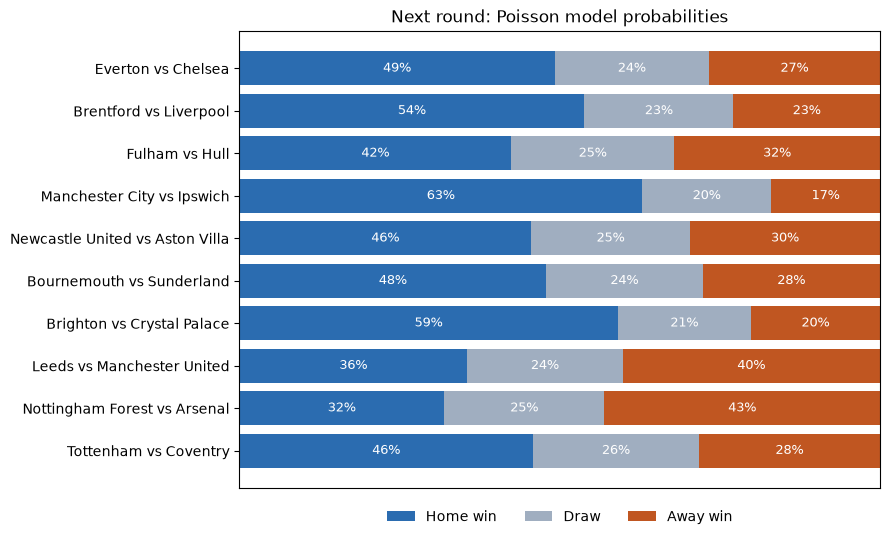

In [7]:
fig, ax = plt.subplots(figsize=(9, 0.45 * len(poi) + 1))
labels = (poi["home_team"] + " vs " + poi["away_team"]).to_list()[::-1]
left = np.zeros(len(poi))
for col, name, color in [("p_H", "Home win", "#2b6cb0"), ("p_D", "Draw", "#a0aec0"), ("p_A", "Away win", "#c05621")]:
    vals = poi[col].to_numpy()[::-1]
    ax.barh(labels, vals, left=left, color=color, label=name)
    for y, (l, v) in enumerate(zip(left, vals)):
        if v >= 0.12:
            ax.text(l + v / 2, y, f"{v:.0%}", ha="center", va="center", color="white", fontsize=9)
    left += vals
ax.set_xlim(0, 1)
ax.set_xticks([])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3, frameon=False)
ax.set_title("Next round: Poisson model probabilities")
plt.tight_layout()
plt.show()

## 4. Save this run's predictions

Saved with today's date. Running again on the same day overwrites that day's file. Only predictions made
**before** the match day are scored later, so a prediction can never be "made" after kickoff.

In [8]:
TODAY = pd.Timestamp.today().normalize()
if SAVE_PREDICTIONS and not poi.empty:
    path = save_predictions(preds, TODAY)
    print(f"Saved {preds['model'].notna().sum()} predictions to {path.relative_to(PROJECT_ROOT)}")
else:
    print("Not saved.")

Saved 20 predictions to data/predictions/predictions_made_2026-10-14.csv


## 5. How did earlier predictions do?

All saved predictions whose matches have now been played, scored with the same measures as notebook 03.
After the first run this section is empty. It fills up week by week as you refresh the data.
A handful of matches says very little, so judge these numbers only after several rounds.

In [9]:
scored = score_saved_predictions(load_saved_predictions(), matches)
if scored.empty:
    print("No saved predictions have been played yet. Come back after the next round, "
          "with FORCE_DOWNLOAD = True.")
else:
    n = scored.drop_duplicates(["date", "home_team", "away_team"]).shape[0]
    print(f"{n} predicted matches have been played.\n")
    by_model = {m: g for m, g in scored.groupby("model")}
    results = next(iter(by_model.values()))["result"].to_numpy()
    print(score_table(results, {m: g[PROB_COLS].to_numpy() for m, g in by_model.items()}).round(3))

No saved predictions have been played yet. Come back after the next round, with FORCE_DOWNLOAD = True.


In [10]:
if not scored.empty:
    p = scored[scored["model"] == "Poisson"].copy()
    p["prediction (H/D/A)"] = [f"{h:.0%} / {d:.0%} / {a:.0%}" for h, d, a in p[PROB_COLS].to_numpy()]
    p["score"] = p["home_goals"].astype(int).astype(str) + "-" + p["away_goals"].astype(int).astype(str)
    p["chance given to result"] = p.apply(lambda r: f"{r['p_' + r['result']]:.0%}", axis=1)
    p["favourite won?"] = p[PROB_COLS].to_numpy().argmax(axis=1) == p["result"].map(CLASSES.index).to_numpy()
    p["result"] = p["result"].map({"H": "home win", "D": "draw", "A": "away win"})
    p["date"] = p["date"].dt.date
    display(p[["date", "home_team", "away_team", "prediction (H/D/A)", "score", "result",
               "chance given to result", "favourite won?"]])

## 6. Predict any match, past or future

Pick two teams and a date, written as `pd.Timestamp("2025-03-16")` (year-month-day).

The models are **retrained on matches before that date only**, and the form features also use only
earlier matches. So for a **past match** this is a fair prediction: the model has not seen that result
or anything after it. If the match was played, the real score is shown next to the prediction.
For a **future date** it is a normal prediction from the latest form.

Both teams need at least 5 earlier Premier League matches in the data (from August 2016).

**Finding a past match:** set a team and season below to list its matches with their dates.
Season codes: `2425` = 2024/25, `2526` = 2025/26, `2627` = 2026/27.

In [11]:
TEAM = "Arsenal"
SEASON = 2526

team_games = matches[(matches["season"] == SEASON)
                     & ((matches["home_team"] == TEAM) | (matches["away_team"] == TEAM))]
print(team_games.assign(date=team_games["date"].dt.date)[
    ["date", "home_team", "home_goals", "away_goals", "away_team"]].to_string(index=False))

      date               home_team  home_goals  away_goals               away_team
2025-08-17       Manchester United           0           1                 Arsenal
2025-08-23                 Arsenal           5           0                   Leeds
2025-08-31               Liverpool           1           0                 Arsenal
2025-09-13                 Arsenal           3           0       Nottingham Forest
2025-09-21                 Arsenal           1           1         Manchester City
2025-09-28        Newcastle United           1           2                 Arsenal
2025-10-04                 Arsenal           2           0                West Ham
2025-10-18                  Fulham           0           1                 Arsenal
2025-10-26                 Arsenal           1           0          Crystal Palace
2025-11-01                 Burnley           0           2                 Arsenal
2025-11-08              Sunderland           2           2                 Arsenal
2025

In [12]:
from src.predict import predict_match_as_of

HOME_TEAM = "Liverpool"
AWAY_TEAM = "Manchester City"
MATCH_DATE = pd.Timestamp("2026-10-11")

one = predict_match_as_of(matches, HOME_TEAM, AWAY_TEAM, MATCH_DATE)
if one["model"].isna().any():
    print(one["note"].iloc[0])
else:
    print(f"{HOME_TEAM} vs {AWAY_TEAM}, {MATCH_DATE:%d %B %Y}")
    print(f"Models trained on {one['trained_on'].iloc[0]} matches played before this date.\n")
    for _, r in one.iterrows():
        extra = (f"   expected goals {r['home_xg_pred']:.2f}-{r['away_xg_pred']:.2f}, "
                 f"likeliest score {r['likely_score']} ({r['likely_score_prob']:.0%})") if r["model"] == "Poisson" else ""
        print(f"  {r['model']:<9} home {r['p_H']:.0%}  draw {r['p_D']:.0%}  away {r['p_A']:.0%}{extra}")
    if "actual_result" in one:
        names = {"H": "home win", "D": "draw", "A": "away win"}
        r = one.iloc[0]
        fav = ["H", "D", "A"][int(np.argmax(r[PROB_COLS].to_numpy(dtype=float)))]
        print(f"\nActual result: {r['actual_score']} ({names[r['actual_result']]}). "
              f"The model gave this {r['p_' + r['actual_result']]:.0%}; "
              f"its favourite ({names[fav]}) {'was right' if fav == r['actual_result'] else 'was wrong'}.")
    else:
        print("\nNot played yet (or no match between these teams on this date).")

Liverpool vs Manchester City, 11 October 2026
Models trained on 3707 matches played before this date.

  Poisson   home 28%  draw 24%  away 48%   expected goals 1.22-1.68, likeliest score 1-1 (11%)
  Logistic  home 27%  draw 24%  away 50%

Actual result: 0-3 (away win). The model gave this 48%; its favourite (away win) was right.
